In [1]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device)

Cihaz: cpu


In [2]:
MEAN, STD = 0.1307, 0.3081
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,))
])

full_train = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set   = datasets.MNIST("data", train=False, download=True, transform=transform)

train_set, val_set = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)

print(f"Train: {len(train_set)}, Validation: {len(val_set)}, Test: {len(test_set)}")

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 612kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.40MB/s]

Train: 50000, Validation: 10000, Test: 10000


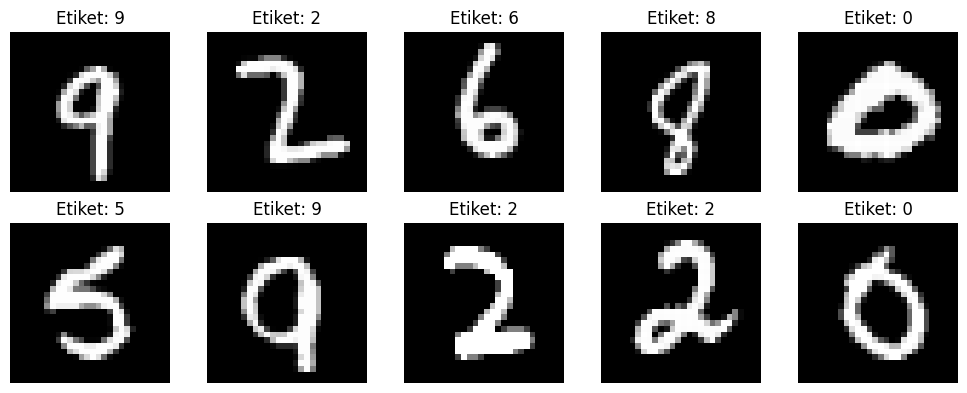

In [3]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(f"Etiket: {lbl.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# Hiperparametreler (raporda bunları yazacaksınız)
HIDDEN1 = 256
HIDDEN2 = 128
LEARNING_RATE = 0.001
EPOCHS = 10

model = nn.Sequential(
    nn.Flatten(),                 # 28x28 resmi 784 sayılık düz bir listeye çevirir
    nn.Linear(784, HIDDEN1),      # 1. gizli katman
    nn.ReLU(),
    nn.Linear(HIDDEN1, HIDDEN2),  # 2. gizli katman
    nn.ReLU(),
    nn.Linear(HIDDEN2, 10)        # çıkış: 10 rakam için 10 skor
).to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)


In [5]:
def run_epoch(loader, train=False):
    if train:
        model.train()
    else:
        model.eval()

    total_loss, correct, total = 0, 0, 0

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)

    return total_loss / total, correct / total

In [6]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start = time.time()

for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
          f"Val Loss: {va_loss:.4f} Acc: {va_acc:.4f}")

train_time = time.time() - start
print(f"\nEğitim süresi: {train_time:.1f} saniye")

Epoch 1/10 | Train Loss: 0.2488 Acc: 0.9263 | Val Loss: 0.1465 Acc: 0.9534
Epoch 2/10 | Train Loss: 0.1004 Acc: 0.9689 | Val Loss: 0.1305 Acc: 0.9616
Epoch 3/10 | Train Loss: 0.0683 Acc: 0.9784 | Val Loss: 0.1133 Acc: 0.9666
Epoch 4/10 | Train Loss: 0.0510 Acc: 0.9830 | Val Loss: 0.0945 Acc: 0.9742
Epoch 5/10 | Train Loss: 0.0412 Acc: 0.9866 | Val Loss: 0.0927 Acc: 0.9731
Epoch 6/10 | Train Loss: 0.0323 Acc: 0.9894 | Val Loss: 0.0887 Acc: 0.9759
Epoch 7/10 | Train Loss: 0.0303 Acc: 0.9900 | Val Loss: 0.0965 Acc: 0.9752
Epoch 8/10 | Train Loss: 0.0261 Acc: 0.9917 | Val Loss: 0.0928 Acc: 0.9778
Epoch 9/10 | Train Loss: 0.0214 Acc: 0.9928 | Val Loss: 0.1100 Acc: 0.9745
Epoch 10/10 | Train Loss: 0.0204 Acc: 0.9934 | Val Loss: 0.1039 Acc: 0.9774

Eğitim süresi: 156.9 saniye


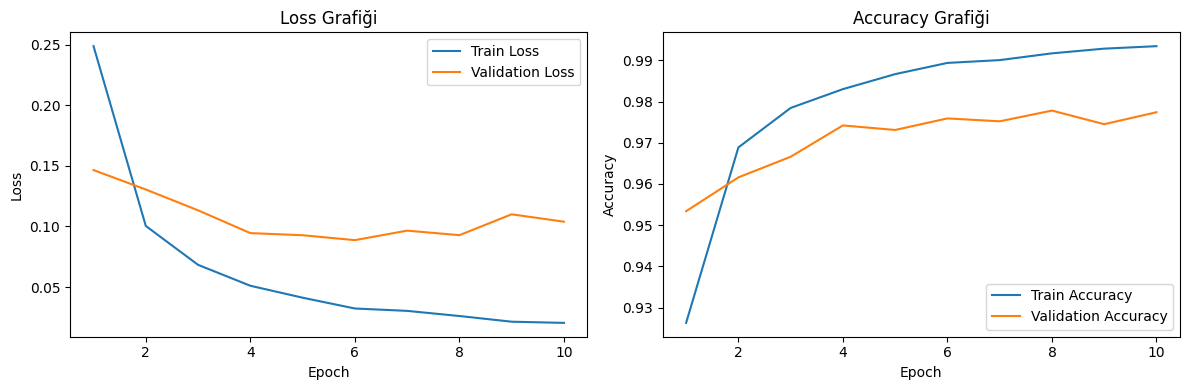

In [7]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4))

# Loss grafiği
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Grafiği")
plt.legend()

# Accuracy grafiği
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], label="Train Accuracy")
plt.plot(epochs_range, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Grafiği")
plt.legend()

plt.tight_layout()
plt.savefig("loss_accuracy_grafik.png", dpi=150)
plt.show()

In [8]:
test_loss, test_acc = run_epoch(test_loader, train=False)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.0974
Test Accuracy: 0.9787


Bulunan rakam sayısı: 11 (11 olmalı)


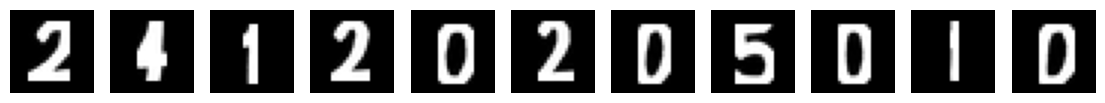

In [13]:
!pip install pillow-heif -q

import numpy as np, os
from PIL import Image, ImageOps
from scipy import ndimage
from pillow_heif import register_heif_opener
register_heif_opener()

# 1) Fotoğrafı aç, gri tonlamaya çevir
img = ImageOps.exif_transpose(Image.open("/IMG_3374.png")).convert("L")
a = np.array(img).astype(float)

# 2) Kâğıttaki gölgeleri düzelt, mürekkebi bul
bg = ndimage.gaussian_filter(a, 60)
norm = np.clip(a / (bg + 1e-6), 0, 1)
ink = norm < 0.80
ink = ndimage.binary_opening(ink, iterations=1)

# 3) Rakamları soldan sağa ayır
cols = ink.sum(axis=0) > 0
cols = ndimage.binary_closing(cols, structure=np.ones(15))
lab, n = ndimage.label(cols)
aralıklar = []
for sl in ndimage.find_objects(lab):
    x0, x1 = sl[0].start, sl[0].stop
    if x1 - x0 >= 10:
        aralıklar.append((x0, x1))
print("Bulunan rakam sayısı:", len(aralıklar), "(11 olmalı)")

# 4) Her rakamı MNIST formatına çevir
def mnist_yap(crop):
    ys, xs = np.where(crop)
    crop = crop[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = crop.shape
    kalinlik = max(2, int(max(h, w) * 0.09))
    crop = ndimage.binary_dilation(crop, iterations=kalinlik)  # çizgiyi kalınlaştır
    pil = Image.fromarray((crop * 255).astype(np.uint8))
    h, w = crop.shape
    s = 20.0 / max(h, w)                                       # 20x20 kutuya sığdır
    pil = pil.resize((max(1, round(w*s)), max(1, round(h*s))), Image.LANCZOS)
    arr = np.array(pil).astype(float)
    canvas = np.zeros((28, 28))
    ph, pw = arr.shape
    canvas[(28-ph)//2:(28-ph)//2+ph, (28-pw)//2:(28-pw)//2+pw] = arr
    cy, cx = ndimage.center_of_mass(canvas)                    # ağırlık merkezine göre ortala
    canvas = ndimage.shift(canvas, (round(14-cy), round(14-cx)), order=1)
    return np.clip(canvas, 0, 255).astype(np.uint8)

os.makedirs("my_digits", exist_ok=True)
rakamlar = []
for i, (x0, x1) in enumerate(aralıklar):
    d = mnist_yap(ink[:, x0:x1])
    Image.fromarray(d).save(f"my_digits/digit_{i}.png")
    rakamlar.append(d)

# 5) Sonucu göster
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(rakamlar), figsize=(14, 2))
for ax, d in zip(axes, rakamlar):
    ax.imshow(d, cmap="gray"); ax.axis("off")
plt.savefig("my_digits/hazirlanan_rakamlar.png", dpi=150, bbox_inches="tight")
plt.show()

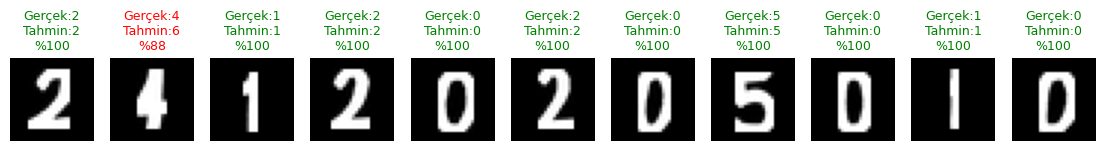

Gerçek numara : 24120205010
Model tahmini : 26120205010
Doğru: 10/11  (%90.9)


In [14]:
GERCEK = "24120205010"

x = torch.tensor(np.stack(rakamlar) / 255.0, dtype=torch.float32).unsqueeze(1)
x = (x - MEAN) / STD          # MNIST ile aynı normalizasyon

model.eval()
with torch.no_grad():
    olasilik = torch.softmax(model(x.to(device)), dim=1).cpu()

tahmin = olasilik.argmax(1)
guven = olasilik.max(1).values

dogru = 0
fig, axes = plt.subplots(1, len(tahmin), figsize=(14, 2.5))
for i, ax in enumerate(axes):
    ok = str(tahmin[i].item()) == GERCEK[i]
    dogru += ok
    ax.imshow(rakamlar[i], cmap="gray")
    ax.set_title(f"Gerçek:{GERCEK[i]}\nTahmin:{tahmin[i].item()}\n%{guven[i]*100:.0f}",
                 color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.savefig("my_digits/tahmin_sonuclari.png", dpi=150, bbox_inches="tight")
plt.show()

print("Gerçek numara :", GERCEK)
print("Model tahmini :", "".join(str(t.item()) for t in tahmin))
print(f"Doğru: {dogru}/{len(GERCEK)}  (%{dogru/len(GERCEK)*100:.1f})")

In [15]:
i = 1  # 2. rakam (4)
ilk3 = olasilik[i].topk(3)
for p, c in zip(ilk3.values, ilk3.indices):
    print(f"Rakam {c.item()}: %{p.item()*100:.1f}")

Rakam 6: %88.3
Rakam 4: %11.3
Rakam 0: %0.3


In [16]:
!zip -r sonuclar.zip my_digits loss_accuracy_grafik.png
from google.colab import files
files.download("sonuclar.zip")

  adding: my_digits/ (stored 0%)
  adding: my_digits/digit_6.png (stored 0%)
  adding: my_digits/digit_7.png (stored 0%)
  adding: my_digits/digit_5.png (stored 0%)
  adding: my_digits/tahmin_sonuclari.png (deflated 13%)
  adding: my_digits/digit_2.png (stored 0%)
  adding: my_digits/digit_8.png (stored 0%)
  adding: my_digits/digit_0.png (stored 0%)
  adding: my_digits/digit_4.png (stored 0%)
  adding: my_digits/digit_1.png (stored 0%)
  adding: my_digits/digit_10.png (stored 0%)
  adding: my_digits/digit_9.png (deflated 1%)
  adding: my_digits/digit_3.png (stored 0%)
  adding: my_digits/hazirlanan_rakamlar.png (deflated 15%)
  adding: loss_accuracy_grafik.png (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>